In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M



In [14]:
def dist(omega, mu, sign_array):

    ### returns an array which gives distance from point 3,2.3 fro given omega , mu array 

    A = np.sqrt((omega - 3)**2 + (mu - 2.3)**2)

    return  A*sign_array

In [8]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L0
OMEGAL0 = np.linspace(2.7, 4.5, NUM)
MUL0 = OMEGAL0* 2.8 -3 * 2.8 + 2.3
change_pointl0 = np.abs(OMEGAL0 -3).argmin()

##L0 perp
OMEGAL0perp = np.linspace(1.8, 4, NUM)
MUL0perp = OMEGAL0perp *(-1/2.8) + (3 / 2.8) + 2.3
change_pointl0perp = np.abs(OMEGAL0perp -3).argmin()

##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2

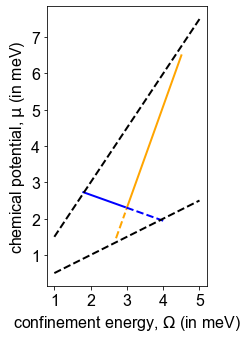

In [34]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))


# Plot lines with different labels
plt.plot(OMEGAL0[:change_pointl0],  MUL0[:change_pointl0], lw=2, label='L1', linestyle='dashed', color='orange')
plt.plot(OMEGAL0[change_pointl0:],  MUL0[change_pointl0:], lw=2, label='L1', color='orange')
plt.plot(OMEGAL0perp[:change_pointl0perp],  MUL0perp[:change_pointl0perp], lw=2, label='L1', color='blue')
plt.plot(OMEGAL0perp[change_pointl0perp:],  MUL0perp[change_pointl0perp:], lw=2, label='L1', linestyle='dashed', color='blue')
plt.plot(OMEGAS1, MUS1, lw=2, linestyle='dashed', color='black', label=f'subband 0')
plt.plot(OMEGAS2, MUS2, lw=2, linestyle='dashed', color='black', label=f'subband 1')

# Set axis limits
#plt.ylim(ymax=5, ymin=0)
#plt.xlim(xmin=1)

# Add labels
plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
plt.ylabel(r'chemical potential, $\mathrm{\mu}$ (in meV)')

# Dynamically scale legend font size based on figure size
fig_width, fig_height = f.get_size_inches()
font_size = min(fig_width, fig_height) * 2  # Proportional font size

# Add the legend with the scaled font size
#plt.legend(loc='upper left', prop={'size': font_size}, fontsize=10)

# Set the aspect ratio to 1 using plt.gca() to get the current axes
#plt.gca().set_aspect('equal')
plt.gca().set_aspect(1)

plt.xticks(np.array([1,2,3,4,5]))

#plt.text(3, 0.5,r'subband 0', fontsize=14)
#plt.text(3.5, 4,r'subband 1', fontsize=14)
#plt.text(1.2, 4.2, r'subband 2', fontsize=14)

# Show plot
plt.tight_layout()
plt.show()


In [11]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_L = 20
ALPHAT_C = 400 
K = 8 

In [12]:
### DATA FOR L0 linear 

Ep_li_1d = np.empty((NUM,K))

for i in range(NUM):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL0[i], ALPHAT_L, DELTA, MEFF_SC, MEFF_SM, MUL0[i], MUL0[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_L0_omega_from_{}_to_{}_num_{}.npy".format(round(OMEGAL0[0],2), round(OMEGAL0[-1],2), NUM), Ep_li_1d)


0
5
10
15
20
25
30
35
40
45
50


In [13]:
### DATA FOR L0 perp linear 

Ep_li_1d = np.empty((NUM,K))

for i in range(NUM):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL0perp[i], ALPHAT_L, DELTA, MEFF_SC, MEFF_SM, MUL0perp[i], MUL0perp[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_L0_perp_omega_from_{}_to_{}_num_{}.npy".format(round(OMEGAL0perp[0],2), round(OMEGAL0perp[-1],2), NUM), Ep_li_1d)


0
5
10
15
20
25
30
35
40
45
50


In [20]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L0
OMEGAL0 = np.linspace(2.7, 4.5, NUM)
MUL0 = OMEGAL0* 2.8 -3 * 2.8 + 2.3
change_pointl0 = np.abs(OMEGAL0 -3).argmin()
S0 = np.where(OMEGAL0>=3, 1, -1)
RL0 = dist(OMEGAL0, MUL0,S0)

##L0 perp
OMEGAL0perp = np.linspace(1.8, 4, NUM)
MUL0perp = OMEGAL0perp *(-1/2.8) + (3 / 2.8) + 2.3
change_pointl0perp = np.abs(OMEGAL0perp -3).argmin()
S0perp = np.where(OMEGAL0perp>=3, -1, 1)
RL0perp = dist(OMEGAL0perp, MUL0perp,S0perp)

##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2


NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_L = 20
ALPHAT_C = 400 
K = 8 


Eli_L0 = np.load("linear_E_L0_omega_from_2.7_to_4.5_num_51.npy")
Eli_L0perp = np.load("linear_E_L0_perp_omega_from_1.8_to_4.0_num_51.npy")

##finding spin splitting by delta at origin pt (3, 2.3 in this case) for plotting purposes
index_org= np.argmin(np.abs(RL0))
Es_org = (Eli_L0[index_org,K//2+1]-Eli_L0[index_org,K//2])/DELTA



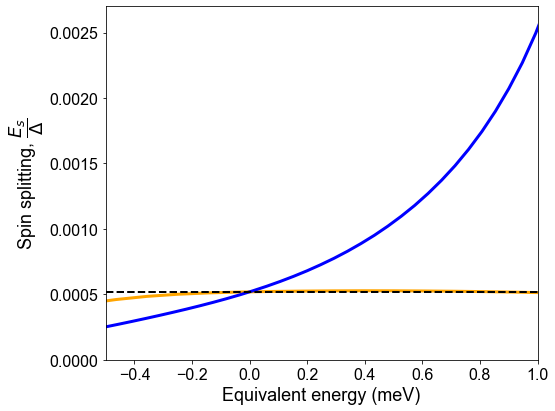

In [36]:
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(8, 6))  # Define figure size

ax.plot(RL0, (Eli_L0[:,K//2+1]-Eli_L0[:,K//2])/DELTA, color='orange', lw=3)
ax.plot(RL0perp, (Eli_L0perp[:,K//2+1]-Eli_L0perp[:,K//2])/DELTA, color='blue', lw=3)
ax.axhline(y=Es_org, color='black', linestyle='--', lw=2)

ax.set_xlabel(r'Equivalent energy (meV)', fontsize=18)  # X-axis label
ax.set_ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=18)  # Y-axis label
#ax.grid(True)  # Add grid for better readability
#ax.legend()  # Add legend

plt.xlim(xmax=1, xmin=-0.5)
plt.ylim(ymax= 0.0027, ymin=0.000)
plt.tight_layout()
plt.show()